## MODIS Fire 8-Day (14A2) with Planetary Computer

Adapted from the official Planetary Computer MODIS fire example and configured for collection `modis-14A2-061`.

### Environment setup
Run this once if your environment is missing dependencies.

In [1]:
import numpy as np
import planetary_computer
import pystac_client
import rasterio
import rich.table
import xarray as xr
from dash import Dash, Input, Output, dcc, html
import plotly.express as px
from rasterio.warp import transform_bounds
from rasterio.windows import Window, from_bounds

### Data access

In [2]:
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

### Query for available data
Set your bbox and date steps below.

In [8]:
# Example area near Dixie wildfire (California)
latitude = 40.7310
longitude = -122.9420
location = [longitude, latitude]
geometry = {
    "type": "Point",
    "coordinates": location,
}

datetimes = [
    "2021-07-12",
    "2021-07-20",
    "2021-07-28",
    "2021-08-05",
    "2021-08-13",
    "2021-08-21",
]

buffer = 0.7
bbox = [longitude - buffer, latitude - buffer, longitude + buffer, latitude + buffer]
items = {}

for dt in datetimes:
    print(f"Fetching {dt}")
    search = catalog.search(
        collections=["modis-14A2-061"],
        intersects=geometry,
        datetime=dt,
    )
    results = search.item_collection()
    if len(results) > 0:
        items[dt] = results[0]

print(items)

Fetching 2021-07-12
Fetching 2021-07-20
Fetching 2021-07-28
Fetching 2021-08-05
Fetching 2021-08-13
Fetching 2021-08-21
{'2021-07-12': <Item id=MYD14A2.A2021193.h08v04.061.2021202231138>, '2021-07-20': <Item id=MYD14A2.A2021201.h08v04.061.2021210025058>, '2021-07-28': <Item id=MYD14A2.A2021209.h08v04.061.2021218015513>, '2021-08-05': <Item id=MYD14A2.A2021217.h08v04.061.2021226035858>, '2021-08-13': <Item id=MYD14A2.A2021225.h08v04.061.2021234033430>, '2021-08-21': <Item id=MYD14A2.A2021233.h08v04.061.2021243064108>}


### Available assets

In [4]:
first_key = next(iter(items))
t = rich.table.Table("Key", "Title")
for key, asset in items[first_key].assets.items():
    t.add_row(key, asset.title)
t

┏━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Key              ┃ Title                                             ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ QA               │ Pixel quality indicators                          │
│ hdf              │ Source data containing all bands                  │
│ FireMask         │ Confidence of fire                                │
│ metadata         │ Federal Geographic Data Committee (FGDC) Metadata │
│ tilejson         │ TileJSON with default rendering                   │
│ rendered_preview │ Rendered preview                                  │
└──────────────────┴───────────────────────────────────────────────────┘

### Load FireMask data

In [5]:
def window_for_bbox(ds, bbox_wgs84):
    west, south, east, north = bbox_wgs84
    minx, miny, maxx, maxy = transform_bounds(
        "EPSG:4326", ds.crs, west, south, east, north, densify_pts=21
    )
    candidate = from_bounds(minx, miny, maxx, maxy, transform=ds.transform)
    bounded = candidate.intersection(Window(0, 0, ds.width, ds.height))
    if bounded.width <= 0 or bounded.height <= 0:
        return None
    return bounded.round_offsets().round_lengths()

arrays = []
timestamps = []

for dt in sorted(items.keys()):
    item = items[dt]
    asset = item.assets.get("FireMask")
    if asset is None or not asset.href:
        continue

    href = planetary_computer.sign(asset.href)
    with rasterio.open(href) as ds:
        window = window_for_bbox(ds, bbox)
        if window is None:
            continue

        band = ds.read(1, window=window, masked=True).astype("float32")
        arr = np.where(band.mask, np.nan, band.data)

        if arrays and arr.shape != arrays[0].shape:
            h = min(arr.shape[0], arrays[0].shape[0])
            w = min(arr.shape[1], arrays[0].shape[1])
            arrays = [a[:h, :w] for a in arrays]
            arr = arr[:h, :w]

        arrays.append(arr)
        if item.datetime is not None:
            timestamps.append(np.datetime64(item.datetime))
        else:
            timestamps.append(np.datetime64(dt))

if not arrays:
    raise ValueError("No FireMask rasters were loaded for this bbox/date range")

stack = np.stack(arrays, axis=0)
data = xr.Dataset(
    {"FireMask": (("time", "y", "x"), stack)},
    coords={
        "time": np.array(timestamps, dtype="datetime64[ns]"),
        "y": np.arange(stack.shape[1]),
        "x": np.arange(stack.shape[2]),
    },
)
data = data.where(data < 10, drop=True)
data

<xarray.Dataset> Size: 1MB
Dimensions:   (time: 6, y: 168, x: 363)
Coordinates:
  * time      (time) datetime64[ns] 48B 2021-07-12 2021-07-20 ... 2021-08-21
  * y         (y) int64 1kB 0 1 2 3 4 5 6 7 ... 160 161 162 163 164 165 166 167
  * x         (x) int64 3kB 0 1 2 3 4 5 6 7 ... 355 356 357 358 359 360 361 362
Data variables:
    FireMask  (time, y, x) float32 1MB 3.0 3.0 3.0 3.0 3.0 ... 5.0 5.0 5.0 5.0

### Display the data

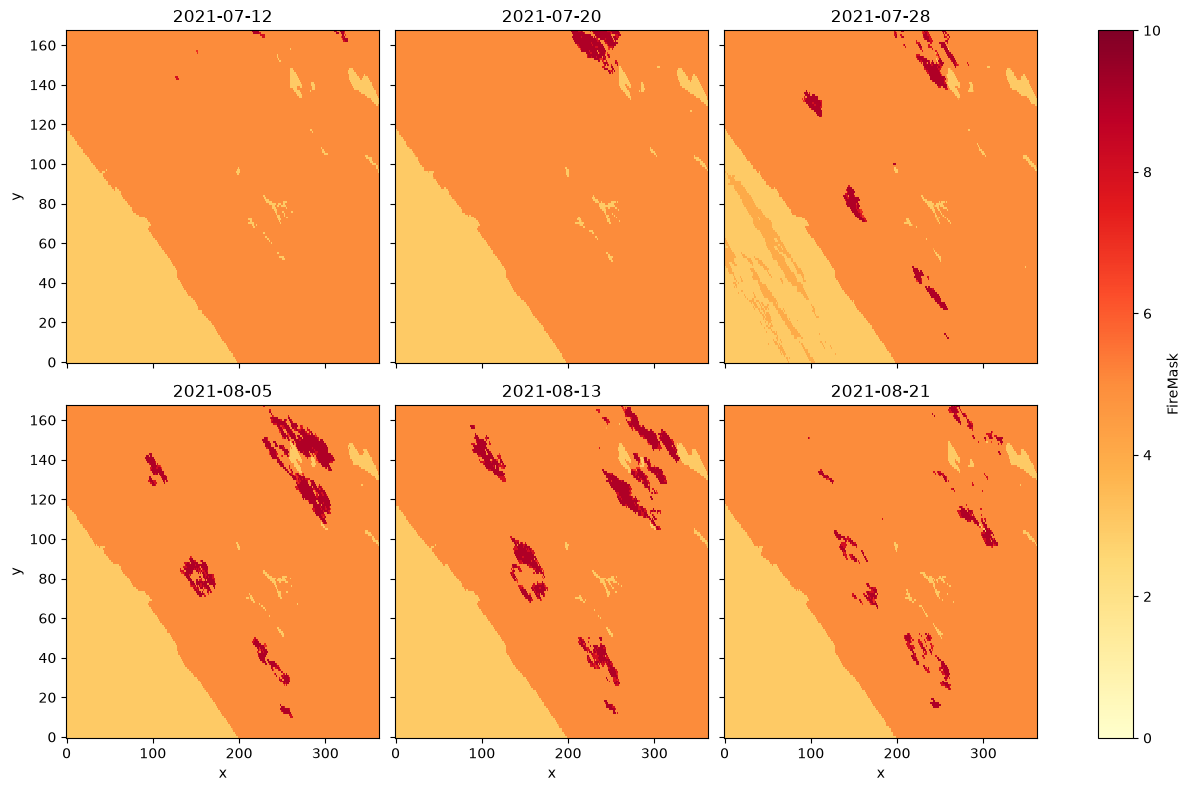

In [9]:
g = data["FireMask"].plot.imshow(
    cmap="YlOrRd", col="time", vmin=0, vmax=10, col_wrap=3, size=4
)
labels = data["FireMask"].time.to_pandas().dt.strftime("%Y-%m-%d")
for ax, dt in zip(g.axs.flat, labels):
    ax.set_title(dt)

In [10]:
# Keep only probable fire classes for interactive playback (7, 8, 9)
fire_only = data.where(data >= 7)

fire_dates = [str(ts)[:10] for ts in fire_only.time.values]

def build_frame_figure(idx: int):
    arr = fire_only.FireMask.isel(time=idx)
    fig = px.imshow(
        arr,
        color_continuous_scale="YlOrRd",
        zmin=7,
        zmax=9,
        origin="upper",
        aspect="equal",
        labels={"color": "FireMask"},
        title=f"MODIS FireMask - {fire_dates[idx]}",
    )
    fig.update_layout(margin=dict(l=20, r=20, t=50, b=20))
    return fig

app = Dash(__name__)
app.layout = html.Div(
    [
        html.H3("MODIS 14A2 Fire Timeline (Dash)"),
        dcc.Graph(id="fire-graph", figure=build_frame_figure(0)),
        dcc.Slider(
            id="day-slider",
            min=0,
            max=max(len(fire_dates) - 1, 0),
            value=0,
            step=1,
            marks={i: d for i, d in enumerate(fire_dates)},
        ),
        html.Div(
            [
                html.Button("Play", id="play-btn", n_clicks=0),
                html.Button("Pause", id="pause-btn", n_clicks=0, style={"marginLeft": "8px"}),
            ],
            style={"marginTop": "10px"},
        ),
        dcc.Interval(id="playback", interval=900, n_intervals=0, disabled=True),
    ],
    style={"maxWidth": "1100px", "margin": "0 auto"},
)

@app.callback(
    Output("fire-graph", "figure"),
    Input("day-slider", "value"),
)
def update_map(idx):
    return build_frame_figure(int(idx or 0))

@app.callback(
    Output("playback", "disabled"),
    Input("play-btn", "n_clicks"),
    Input("pause-btn", "n_clicks"),
    prevent_initial_call=True,
)
def toggle_playback(_play, _pause):
    trigger = app.callback_context.triggered_id
    if trigger == "play-btn":
        return False
    return True

@app.callback(
    Output("day-slider", "value"),
    Input("playback", "n_intervals"),
    Input("day-slider", "value"),
)
def advance_slider(n_intervals, current_value):
    if len(fire_dates) <= 1:
        return 0
    if n_intervals is None:
        return int(current_value or 0)
    return (int(current_value or 0) + 1) % len(fire_dates)

print("Dash app starting on http://127.0.0.1:8061")
app.run(host="127.0.0.1", port=8061, debug=False)

Dash app starting on http://127.0.0.1:8061


[2026-06-22 09:14:09,232] ERROR in app: Exception on /_dash-update-component [POST]
Traceback (most recent call last):
  File "/home/alvaroperez/eps-alvaro-perez/EarthAnalyser/.venv/lib/python3.14/site-packages/flask/app.py", line 1511, in wsgi_app
    response = self.full_dispatch_request()
  File "/home/alvaroperez/eps-alvaro-perez/EarthAnalyser/.venv/lib/python3.14/site-packages/flask/app.py", line 919, in full_dispatch_request
    rv = self.handle_user_exception(e)
  File "/home/alvaroperez/eps-alvaro-perez/EarthAnalyser/.venv/lib/python3.14/site-packages/flask/app.py", line 917, in full_dispatch_request
    rv = self.dispatch_request()
  File "/home/alvaroperez/eps-alvaro-perez/EarthAnalyser/.venv/lib/python3.14/site-packages/flask/app.py", line 902, in dispatch_request
    return self.ensure_sync(self.view_functions[rule.endpoint])(**view_args)  # type: ignore[no-any-return]
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^
  File "/home/alvaroperez/eps